# Improving Montréal towing forecasts

The required OLS model explains borough snow associations, but its first evaluation showed little count-forecast improvement. This extension asks a harder question: **Can tomorrow's borough towing counts be predicted better than simply using yesterday's counts?** It preserves the original OLS analysis and makes no slides.

The forecast horizon is **one day**, updated daily. Lagged towing counts from the preceding day must be available at prediction time. This is different from predicting an entire future year in one shot or warning before an operation starts.

Model choice uses two earlier validation years, July 2023–June 2024 and July 2024–June 2025, with an expanding training window starting January 2021. The selected specification is then fitted through June 2025 and evaluated on July 2025–June 2026. This test year's initial OLS performance was already seen in the earlier analysis, so this extension is exploratory, not a fresh independent confirmation. **No candidate is selected or retuned using its 2025–26 score.**

Primary metric: mean of the 17 borough MASEs, each using its own training lag-seven error scale. Report winter separately and compare naive and seasonal-naive forecasts on the same evaluation rows. Preserve poor results as well as good ones.

In [1]:
from pathlib import Path
import os
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
os.environ['SM_FORMULA_ENGINE']='patsy'
import json, hashlib, platform, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sklearn, scipy, statsmodels
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score
import statsmodels.formula.api as smf
import joblib
from IPython.display import display, Image

roots=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in roots if (p/'part_c/handoff/model_input.csv').exists()),None)
if ROOT is None:
    ROOT=next((p/'Tow_Risk_Project' for p in roots if (p/'Tow_Risk_Project/part_c/handoff/model_input.csv').exists()),None)
assert ROOT is not None,'Keep this folder in the original project, alongside part_c.'
OUT=ROOT/'part_c_improved'
for folder in ['tables','figures','handoff']: (OUT/folder).mkdir(parents=True,exist_ok=True)
source=ROOT/'part_c/handoff/model_input.csv'
data=pd.read_csv(source,encoding='utf-8-sig',parse_dates=['date']).sort_values(['date','borough']).reset_index(drop=True)
assert len(data)==34119 and not data.duplicated(['date','borough']).any()
assert (data.groupby('date').size()==17).all() and not data.isna().any().any()
data['log_tows']=np.log1p(data.tows)
boroughs=sorted(data.borough.unique())
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
versions={m.__name__:m.__version__ for m in [pd,np,scipy,sklearn,statsmodels,matplotlib]}
print('Package versions:',versions)
print('Input:',source)
display(data.head())

Package versions: {'pandas': '2.2.3', 'numpy': '2.5.3', 'scipy': '1.17.0', 'sklearn': '1.8.0', 'statsmodels': '0.14.6', 'matplotlib': '3.9.2'}
Input: C:\Users\tonyt\Downloads\Tow_Risk_Project\Tow_Risk_Project\part_c\handoff\model_input.csv


,date,borough,tows,snow_7c,snow_8_14,snow_1,rain_1,temp_7,dow,month,trend,moving_day,log_tows
0,2021-01-01,Ahuntsic-Cartierville,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0,0.0
1,2021-01-01,Anjou,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0,0.0
2,2021-01-01,Côte-des-Neiges–Notre-Dame-de-Grâce,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0,0.0
3,2021-01-01,LaSalle,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0,0.0
4,2021-01-01,Lachine,0,14.0,10.8,0.0,0.8,-1.828571,4,1,0.0,0,0.0


## 1 Construct features using only earlier dates

Candidate forecast models receive lagged borough counts and rolling summaries, all shifted before calculation. The city-history variant also receives total towing in other boroughs on preceding days. This can reflect an operation already under way elsewhere, but cannot use the target day's city totals.

Weather-only candidates receive calendar and lagged weather variables, including a breakdown of past snowfall timing. No observed counts from the target day enter any model. The original OLS comparator uses the original planned specification. `temp_7` comes from Part C's past-only temperature repair.

Trimming the first 14 days provides a common feature-complete panel for evaluation and advanced-model fitting. The OLS comparator uses all training rows available under the original plan. MASE denominators always use the full training towing series.

In [2]:
g=data.groupby('borough',sort=False)
for lag in [1,2,3,7,14]:
    data[f'tow_lag{lag}']=g.tows.shift(lag)
for window in [3,7,14]:
    data[f'tow_mean{window}']=g.tows.transform(lambda s:s.shift(1).rolling(window).mean())
data['tow_max7']=g.tows.transform(lambda s:s.shift(1).rolling(7).max())
data['tow_change1']=data.tow_lag1-data.tow_lag2
data['log_lag1']=np.log1p(data.tow_lag1)
data['log_lag7']=np.log1p(data.tow_lag7)
daily=data.groupby('date').agg(city_tows=('tows','sum'),snow_1=('snow_1','first')).sort_index()
for lag in [1,2,7]: daily[f'city_lag{lag}']=daily.city_tows.shift(lag)
for window in [3,7]: daily[f'city_mean{window}']=daily.city_tows.shift(1).rolling(window).mean()
daily['snow_2_3']=daily.snow_1.shift(1).rolling(2).sum()
daily['snow_4_7']=daily.snow_1.shift(3).rolling(4).sum()
daily['snow_7_uncapped']=daily.snow_1.rolling(7).sum()
age=[]
last=None
for date,snow in daily.snow_1.items():
    if snow>=5: last=date
    age.append(30 if last is None else min((date-last).days,30))
daily['days_since_snow5']=age
new_daily=[c for c in daily if c not in ['city_tows','snow_1']]
data=data.merge(daily[new_daily],left_on='date',right_index=True,how='left',validate='many_to_one')
data['other_boroughs_lag1']=data.city_lag1-data.tow_lag1
data['log_city_lag1']=np.log1p(data.city_lag1)
data['borough_id']=data.borough.map({b:i for i,b in enumerate(boroughs)}).astype(int)
data['day_of_year']=data.date.dt.dayofyear
calendar_features=['borough_id','dow','month','trend','moving_day','day_of_year']
weather_features=['snow_7c','snow_8_14','snow_1','rain_1','temp_7','snow_2_3','snow_4_7','snow_7_uncapped','days_since_snow5']
own_features=[f'tow_lag{k}' for k in [1,2,3,7,14]]+[f'tow_mean{k}' for k in [3,7,14]]+['tow_max7','tow_change1']
city_features=['city_lag1','city_lag2','city_lag7','city_mean3','city_mean7','other_boroughs_lag1']
feature_sets={
    'weather':calendar_features+weather_features,
    'own_lags':calendar_features+weather_features+own_features,
    'city_lags':calendar_features+weather_features+own_features+city_features,
}
all_features=feature_sets['city_lags']
panel=data.dropna(subset=all_features).copy()
assert panel.date.min()==pd.Timestamp('2021-01-15')
assert np.allclose(panel.tow_lag1, data.groupby('borough').tows.shift(1).loc[panel.index])
feature_notes={
 'calendar':calendar_features,'weather':weather_features,'own_towing_history':own_features,'city_towing_history':city_features,
 'horizon':'One-step ahead, updated daily using preceding observed outcomes, with fitted parameters fixed within each evaluation year.',
 'availability':'Assumes complete borough and city tow counts through yesterday are available before the forecast.'
}
(OUT/'handoff/feature_definitions.json').write_text(json.dumps(feature_notes,indent=2),encoding='utf-8')
print('Advanced-model panel starts:',panel.date.min().date(),'| rows:',len(panel))
print('Maximum feature history: 14 preceding days.')

Advanced-model panel starts: 2021-01-15 | rows: 33881
Maximum feature history: 14 preceding days.


## 2 Declare models and validation rules before opening final-year scores

Three benchmarks use yesterday's count, the same weekday last week, or the previous seven days' mean. Two OLS comparators use the required calendar/weather/borough interaction model, with and without log lag-one and lag-seven towing and log lag-one city towing.

The nonlinear candidates use histogram gradient boosting with absolute-error loss. This targets a median-style count prediction suited to MAE and MASE. Training weights are inverse borough MASE scales so that training loss gives similar emphasis to the primary metric. Borough, weekday and month are native categorical features. Automatic random early stopping is **disabled**. Each predeclared configuration has a fixed number of iterations.

The grid varies only two tree complexities and three information sets, plus a residual-correction variant that starts from yesterday's count. This allows us to distinguish a more flexible weather response from the benefit of recent towing information. A no-weather ablation later measures what the selected forecast gains from weather.

Sources: [scikit-learn histogram gradient boosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) and [FPP3 time-series cross-validation](https://otexts.com/fpp3/tscv.html).

In [3]:
formula='log_tows ~ C(borough) + C(dow) + C(month) + trend + moving_day + snow_7c + snow_8_14 + snow_1 + rain_1 + temp_7 + C(borough):snow_7c'
formula_ar=formula+' + log_lag1 + log_lag7 + log_city_lag1'
configs=[
 {'name':'Naive yesterday','kind':'naive'},
 {'name':'Seasonal naive 7 days','kind':'seasonal'},
 {'name':'Past 7 days mean','kind':'mean7'},
 {'name':'Required weather OLS','kind':'ols'},
 {'name':'OLS plus towing lags','kind':'ar_ols'},
]
for fs in ['weather','own_lags','city_lags']:
    for size,leaves,iters,minleaf in [('small',15,180,70),('medium',31,260,45)]:
        configs.append({'name':f'Boost {fs} {size}','kind':'boost','features':fs,'leaves':leaves,'iterations':iters,'min_leaf':minleaf,'target':'count'})
for size,leaves,iters,minleaf in [('small',15,180,70),('medium',31,260,45)]:
    configs.append({'name':f'Boost naive correction {size}','kind':'boost','features':'city_lags','leaves':leaves,'iterations':iters,'min_leaf':minleaf,'target':'delta'})
folds=[('2023-24','2023-07-01','2024-06-30'),('2024-25','2024-07-01','2025-06-30')]
protocol={'selection':'Lowest mean borough-MASE across the two earlier full-year folds; no final-year tuning.','folds':folds,'configurations':configs,'final_start':'2025-07-01','final_end':'2026-06-30','metric':'Mean of 17 borough MASEs, training seasonal lag-7 scale','random_seed':20261123,'test_status':'Previously inspected for original OLS, so the improved analysis is exploratory.'}
(OUT/'handoff/protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')

def mase_scales(training):
    tr=training.sort_values(['date','borough'])
    return tr.assign(e=(tr.tows-tr.groupby('borough').tows.shift(7)).abs()).groupby('borough').e.mean()

def score(evaluation,pred,scales):
    e=evaluation[['date','borough','tows']].copy()
    e['pred']=np.maximum(np.asarray(pred),0)
    e['absolute_error']=(e.tows-e.pred).abs()
    e['scaled_error']=e.absolute_error/e.borough.map(scales)
    winter=e.date.dt.month.isin([12,1,2,3])
    city_observed=e.groupby('date').tows.sum()
    peak=e.date.map(city_observed).ge(150)
    return {'mase':e.scaled_error.mean(),'mae':e.absolute_error.mean(),'winter_mase':e.loc[winter,'scaled_error'].mean(),'other_mase':e.loc[~winter,'scaled_error'].mean(),'high_activity_mase':e.loc[peak,'scaled_error'].mean(),'r2_count':r2_score(e.tows,e.pred)}

def fit_predict(config,training,evaluation,scales,feature_override=None):
    k=config['kind']
    if k=='naive': return evaluation.tow_lag1.to_numpy(),None
    if k=='seasonal': return evaluation.tow_lag7.to_numpy(),None
    if k=='mean7': return evaluation.tow_mean7.to_numpy(),None
    if k in ['ols','ar_ols']:
        use=training if k=='ols' else training.dropna(subset=['log_lag1','log_lag7','log_city_lag1'])
        fit=smf.ols(formula if k=='ols' else formula_ar,data=use).fit()
        pred=np.maximum(np.expm1(fit.predict(evaluation)),0)
        return pred,fit
    cols=feature_override if feature_override is not None else feature_sets[config['features']]
    tr=training.dropna(subset=all_features)
    categorical=[c for c in ['borough_id','dow','month'] if c in cols]
    fit=HistGradientBoostingRegressor(loss='absolute_error',learning_rate=.07,max_iter=config['iterations'],max_leaf_nodes=config['leaves'],min_samples_leaf=config['min_leaf'],l2_regularization=1.,categorical_features=categorical,early_stopping=False,random_state=20261123)
    target=tr.tows-tr.tow_lag1 if config['target']=='delta' else tr.tows
    weights=1./tr.borough.map(scales)
    fit.fit(tr[cols],target,sample_weight=weights)
    pred=fit.predict(evaluation[cols])
    if config['target']=='delta': pred=pred+evaluation.tow_lag1.to_numpy()
    return np.maximum(pred,0),fit

validation=[]
for fold,start,end in folds:
    tr=data.loc[data.date<pd.Timestamp(start)].copy()
    va=panel.loc[panel.date.between(start,end)].copy()
    scales=mase_scales(tr)
    for cfg in configs:
        begin=time.monotonic()
        pred,fit=fit_predict(cfg,tr,va,scales)
        result={'fold':fold,'model':cfg['name'],**score(va,pred,scales),'fit_seconds':time.monotonic()-begin}
        validation.append(result)
        print(f"{fold} | {cfg['name']:<33} | MASE {result['mase']:.4f}",flush=True)
validation=pd.DataFrame(validation)
validation.to_csv(OUT/'tables/validation_folds.csv',index=False)
ranking=validation.groupby('model')[['mase','mae','winter_mase','other_mase','high_activity_mase']].mean().sort_values('mase')
ranking.to_csv(OUT/'tables/validation_ranking.csv')
# The benchmark can win. Do not force a complex model into first place.
winner_name=ranking.index[0]
winner_config=next(c for c in configs if c['name']==winner_name)
learned_ranking=ranking.loc[[c['name'] for c in configs if c['kind'] in ['ols','ar_ols','boost']]].sort_values('mase')
best_learned_name=learned_ranking.index[0]
best_learned_config=next(c for c in configs if c['name']==best_learned_name)
selection={'winner':winner_name,'winner_config':winner_config,'best_learned':best_learned_name,'best_learned_config':best_learned_config,'selected_before_test':True}
(OUT/'handoff/selected_model.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
print('VALIDATION WINNER:',winner_name)
display(ranking.round(4))

2023-24 | Naive yesterday                   | MASE 0.3422


2023-24 | Seasonal naive 7 days             | MASE 0.5829


2023-24 | Past 7 days mean                  | MASE 0.4399


2023-24 | Required weather OLS              | MASE 0.3446


2023-24 | OLS plus towing lags              | MASE 0.3090


2023-24 | Boost weather small               | MASE 0.3866


... (18 outputs left out)

2024-25 | Boost naive correction small      | MASE 0.5406


2024-25 | Boost naive correction medium     | MASE 0.4852


VALIDATION WINNER: Boost naive correction medium


,mase,mae,winter_mase,other_mase,high_activity_mase
model,,,,,
Boost naive correction medium,0.3772,4.2923,0.8344,0.1500,2.7949
Boost naive correction small,0.4031,4.4834,0.8994,0.1564,2.9959
OLS plus towing lags,0.4610,5.2256,1.0716,0.1575,3.8132
Naive yesterday,0.4850,5.5051,1.0538,0.2023,3.5041
Required weather OLS,0.5000,5.6653,1.1680,0.1680,4.0873
Boost city_lags medium,0.5581,6.8112,1.3080,0.1854,4.8699
Boost own_lags medium,0.5581,6.8112,1.3080,0.1854,4.8699
Boost city_lags small,0.5581,6.8112,1.3080,0.1854,4.8699
Boost own_lags small,0.5581,6.8112,1.3080,0.1854,4.8699


## 3 Evaluate the frozen choices on the final year

Only the validation winner, best learned model and predeclared comparators are evaluated here. No additional hyperparameter or threshold search follows these results. The weather-only boosting comparator is chosen using earlier validation results too. The final year is a sequence of one-day-ahead predictions: actual prior-day counts are available as time advances, but model parameters are fixed after fitting the training period.

The weather ablation uses the best learned boosting configuration and removes every weather feature, refitting without changing its hyperparameters. It is a diagnostic, not another chance to select a new final model.

In [4]:
train=data.loc[data.date<='2025-06-30'].copy()
test=panel.loc[panel.date.between('2025-07-01','2026-06-30')].copy()
assert len(test)==6205
scales=mase_scales(train)
scales.rename('training_lag7_mae').to_csv(OUT/'tables/mase_scales.csv')
weather_names=[c['name'] for c in configs if c['kind']=='boost' and c['features']=='weather']
weather_winner=ranking.loc[weather_names].sort_values('mase').index[0]
eval_names=list(dict.fromkeys(['Naive yesterday','Seasonal naive 7 days','Past 7 days mean','Required weather OLS','OLS plus towing lags',weather_winner,winner_name,best_learned_name]))
predictions=test[['date','borough','tows']].copy()
test_scores=[]
fitted={}
for name in eval_names:
    cfg=next(c for c in configs if c['name']==name)
    pred,fit=fit_predict(cfg,train,test,scales)
    predictions[name]=pred
    fitted[name]=fit
    test_scores.append({'model':name,'role':('validation winner' if name==winner_name else 'comparator'),**score(test,pred,scales)})
if best_learned_config['kind']=='boost':
    no_weather=[c for c in feature_sets[best_learned_config['features']] if c not in weather_features]
    pred,fit=fit_predict(best_learned_config,train,test,scales,feature_override=no_weather)
    predictions['Selected learner without weather']=pred
    test_scores.append({'model':'Selected learner without weather','role':'ablation',**score(test,pred,scales)})
test_scores=pd.DataFrame(test_scores)
test_scores.to_csv(OUT/'tables/final_year_scores.csv',index=False)
predictions.to_csv(OUT/'handoff/final_year_predictions.csv',index=False,encoding='utf-8-sig')
by_borough=[]
for name in predictions.columns[3:]:
    e=test[['borough','tows']].copy()
    e['absolute_error']=np.abs(e.tows-predictions[name])
    per=e.groupby('borough').absolute_error.mean()
    for b in boroughs: by_borough.append({'model':name,'borough':b,'mae':per[b],'mase':per[b]/scales[b]})
by_borough=pd.DataFrame(by_borough)
by_borough.to_csv(OUT/'tables/final_year_borough_scores.csv',index=False,encoding='utf-8-sig')
print('Frozen validation winner:',winner_name)
print('Best learned model selected on validation:',best_learned_name)
display(test_scores.round(4))
if fitted[best_learned_name] is not None:
    joblib.dump({'model':fitted[best_learned_name],'config':best_learned_config,'feature_names':(feature_sets[best_learned_config['features']] if best_learned_config['kind']=='boost' else None),'borough_mapping':{b:i for i,b in enumerate(boroughs)},'versions':versions},OUT/'handoff/best_learned_model.joblib',compress=3)

Frozen validation winner: Boost naive correction medium
Best learned model selected on validation: Boost naive correction medium


,model,role,mase,mae,winter_mase,other_mase,high_activity_mase,r2_count
0,Naive yesterday,comparator,0.9255,10.1605,2.3486,0.2198,6.1470,0.3531
1,Seasonal naive 7 days,comparator,1.6837,19.0442,4.6301,0.2225,7.6040,-0.9532
2,Past 7 days mean,comparator,1.3493,15.0651,3.6755,0.1958,7.1756,-0.0330
3,Required weather OLS,comparator,0.9682,10.8020,2.5534,0.1820,6.7666,0.0455
4,OLS plus towing lags,comparator,0.8494,9.4656,2.2198,0.1698,5.9930,0.2586
5,Boost weather medium,comparator,1.0231,11.9550,2.6537,0.2144,7.2586,-0.0748
6,Boost naive correction medium,validation winner,0.7005,7.7063,1.7878,0.1613,4.7401,0.5538
7,Selected learner without weather,ablation,0.6821,7.5283,1.7264,0.1642,4.5917,0.5802


## 4 Quantify the improvement and examine operation starts

The paired moving-block bootstrap resamples 14-day blocks of **daily average scaled errors**, preserving same-day dependence across boroughs and short-run time dependence. Its intervals describe variability within this test-year sample, conditional on the fitted models. They do not account for the whole model selection process or prove performance will transfer to future winters.

A citywide high-activity day has at least 150 recorded tows, the threshold already used in the analysis plan. An operation start here means the first such day after three consecutive days below 150. This is an activity proxy, not a verified snow-loading start. We sum the borough forecasts and apply the same fixed 150 threshold. Report detections and false warnings without choosing a threshold on the test year.

In [5]:
def daily_losses(name):
    e=test[['date','borough','tows']].copy()
    e['loss']=np.abs(e.tows-predictions[name])/e.borough.map(scales)
    return e.groupby('date').loss.mean()

selected_loss=daily_losses(winner_name)
rng=np.random.default_rng(20261123)
N=len(selected_loss)
B=1200
block=14
starts=rng.integers(0,N,size=(B,int(np.ceil(N/block))))
ix=(starts[:,:,None]+np.arange(block)[None,None,:])%N
ix=ix.reshape(B,-1)[:,:N]
comparisons=[]
for baseline in ['Naive yesterday','Seasonal naive 7 days','Required weather OLS']:
    bl=daily_losses(baseline).to_numpy()
    sl=selected_loss.to_numpy()
    gain=100*(1-sl.mean()/bl.mean())
    draws=100*(1-sl[ix].mean(axis=1)/bl[ix].mean(axis=1))
    low,high=np.quantile(draws,[.025,.975])
    comparisons.append({'selected_model':winner_name,'baseline':baseline,'mase_reduction_pct':gain,'block14_low_pct':low,'block14_high_pct':high})
comparisons=pd.DataFrame(comparisons)
comparisons.to_csv(OUT/'tables/improvement_intervals.csv',index=False)
display(comparisons.round(2))

actual_city=data.groupby('date').tows.sum()
prior_quiet=pd.concat([actual_city.shift(k).lt(150) for k in [1,2,3]],axis=1).all(axis=1)
onsets=(actual_city.ge(150)&prior_quiet).reindex(pd.DatetimeIndex(test.date.unique()))
activity=[]
city_predictions=predictions.groupby('date')[list(predictions.columns[3:])].sum()
for name in city_predictions:
    warning=city_predictions[name].ge(150)
    truth=actual_city.reindex(warning.index).ge(150)
    activity.append({'model':name,'activity_starts':int(onsets.sum()),'starts_warned':int((warning&onsets).sum()),'high_activity_days':int(truth.sum()),'high_activity_days_warned':int((warning&truth).sum()),'false_warning_days':int((warning&~truth).sum()),'total_warning_days':int(warning.sum())})
activity=pd.DataFrame(activity)
activity.to_csv(OUT/'tables/activity_warning_check.csv',index=False)
display(activity)
city_predictions.insert(0,'actual_tows',actual_city.reindex(city_predictions.index))
city_predictions.to_csv(OUT/'tables/citywide_final_year_predictions.csv')

,selected_model,baseline,mase_reduction_pct,block14_low_pct,block14_high_pct
0,Boost naive correction medium,Naive yesterday,24.32,19.38,29.92
1,Boost naive correction medium,Seasonal naive 7 days,58.40,44.34,68.95
2,Boost naive correction medium,Required weather OLS,27.65,16.17,36.60


,model,activity_starts,starts_warned,high_activity_days,high_activity_days_warned,false_warning_days,total_warning_days
0,Naive yesterday,6,0,42,33,9,42
1,Seasonal naive 7 days,6,1,42,15,27,42
2,Past 7 days mean,6,1,42,36,26,62
3,Required weather OLS,6,3,42,17,7,24
4,OLS plus towing lags,6,0,42,31,4,35
5,Boost weather medium,6,0,42,0,0,0
6,Boost naive correction medium,6,2,42,33,2,35
7,Selected learner without weather,6,0,42,30,3,33


## 5 Figures and interpretation

The comparison chart shows final-year forecasting errors, with lower MASE indicating better performance. The time plot focuses on winter, where unusually large towing counts matter. A third chart compares the validation-selected forecast with yesterday's count separately for each borough. None of these charts is a slide.

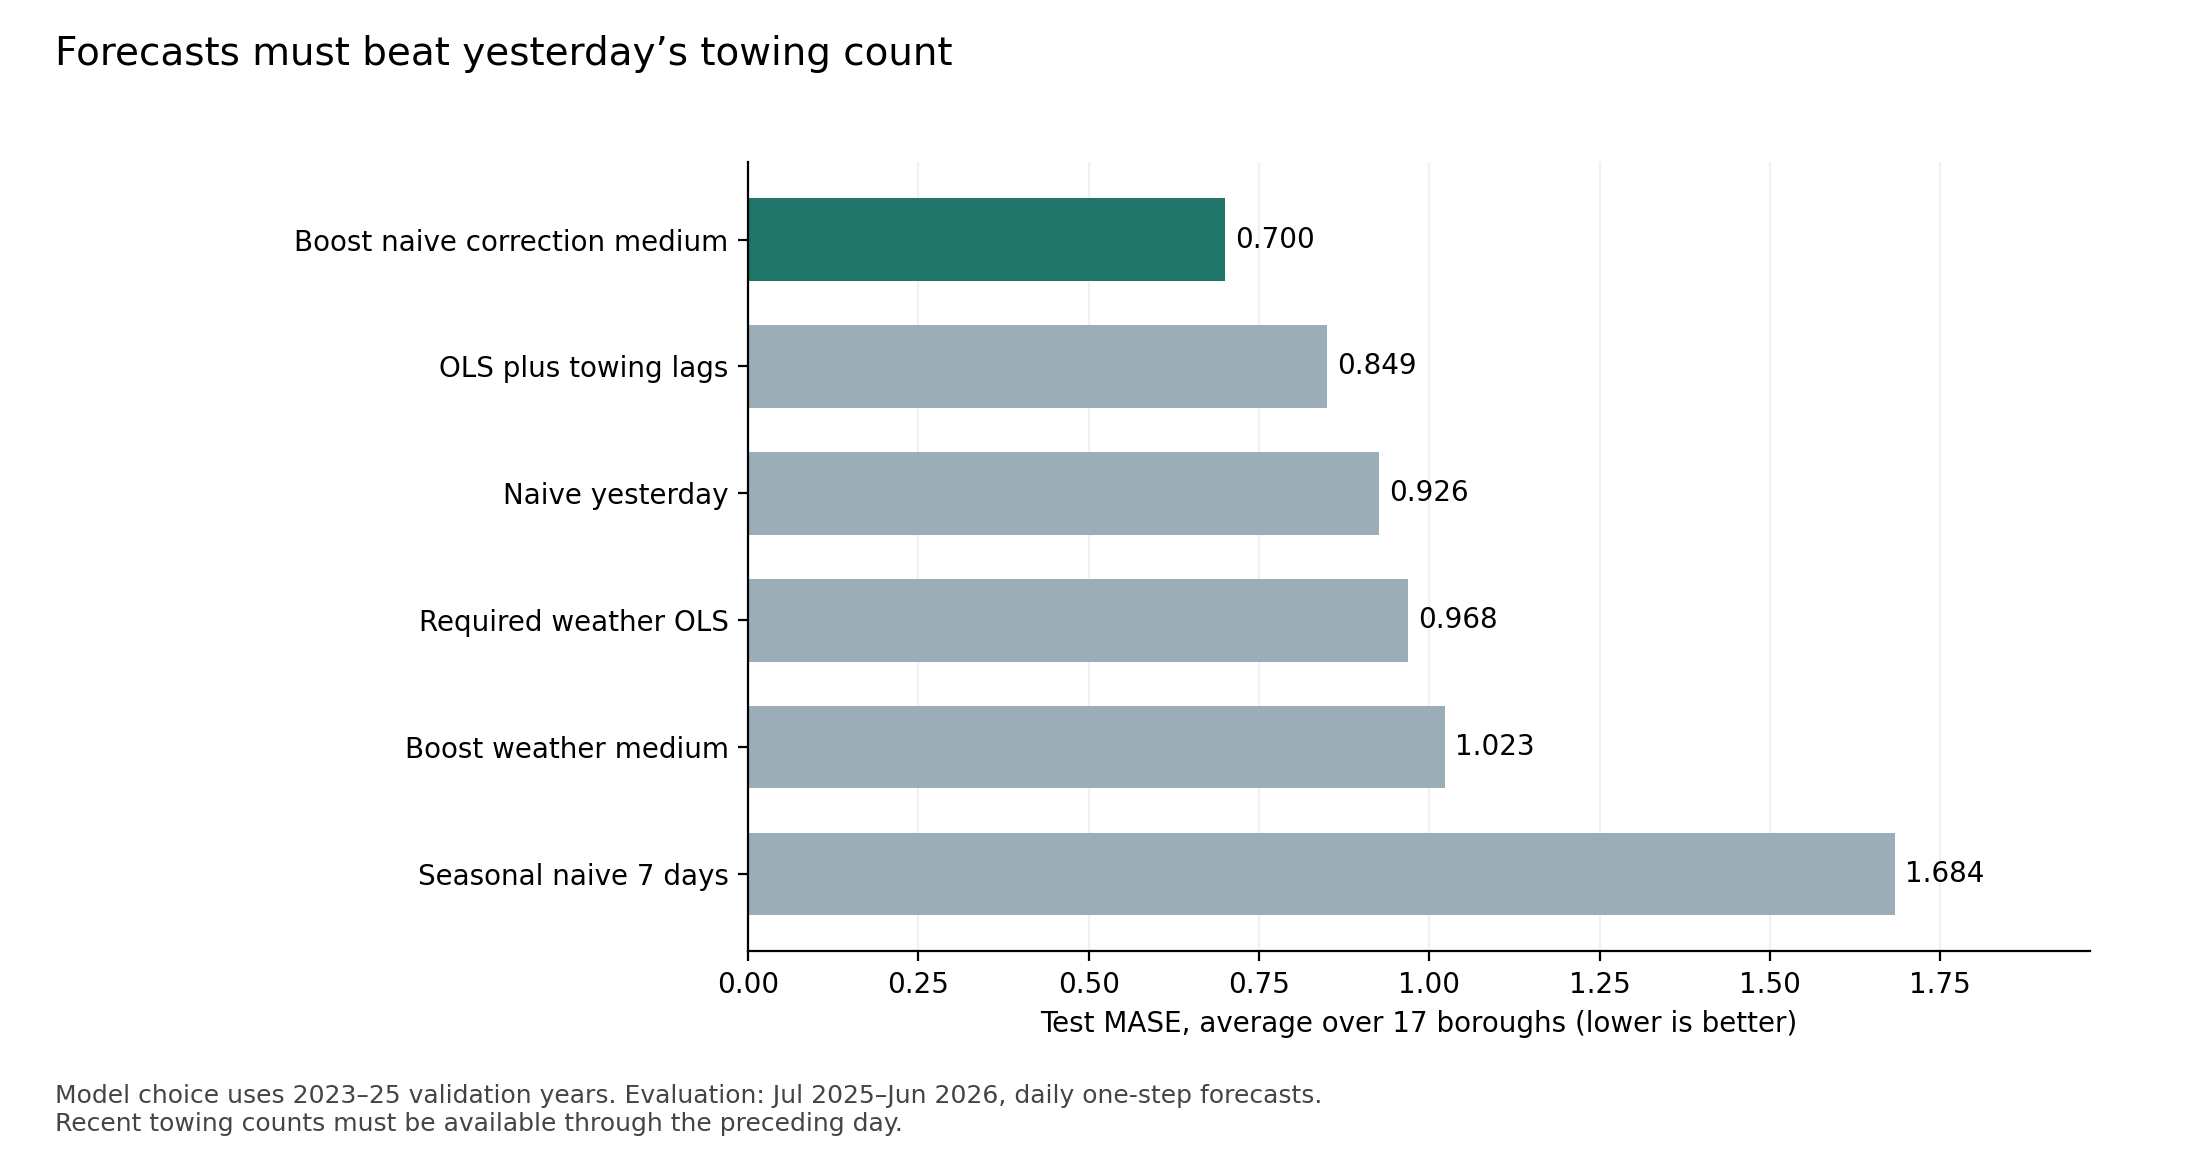

{
  "selection": {
    "winner": "Boost naive correction medium",
    "winner_config": {
      "name": "Boost naive correction medium",
      "kind": "boost",
      "features": "city_lags",
      "leaves": 31,
      "iterations": 260,
      "min_leaf": 45,
      "target": "delta"
    },
    "best_learned": "Boost naive correction medium",
    "best_learned_config": {
      "name": "Boost naive correction medium",
      "kind": "boost",
      "features": "city_lags",
      "leaves": 31,
      "iterations": 260,
      "min_leaf": 45,
      "target": "delta"
    },
    "selected_before_test": true
  },
  "versions": {
    "pandas": "2.2.3",
    "numpy": "2.5.3",
    "scipy": "1.17.0",
    "sklearn": "1.8.0",
    "statsmodels": "0.14.6",
    "matplotlib": "3.9.2"
  },
  "selected_test_mase": 0.7004648216472024,
  "selected_test_mae": 7.7063294138273735,
  "selected_test_r2_count": 0.5538200768769328,
  "naive_test_mase": 0.925511945720016,
  "required_ols_test_mase": 0.968156524218854,
  "

In [6]:
names=list(dict.fromkeys(['Required weather OLS','Naive yesterday','Seasonal naive 7 days','OLS plus towing lags',weather_winner,winner_name,best_learned_name]))
chart=test_scores.set_index('model').loc[names].sort_values('mase')
fig,ax=plt.subplots(figsize=(11,5.8))
colors=['#1e7568' if name==winner_name else '#9baeb7' for name in chart.index]
y=np.arange(len(chart))
ax.barh(y,chart.mase,color=colors,height=.65)
ax.set_yticks(y,chart.index)
ax.invert_yaxis()
for i,v in enumerate(chart.mase): ax.text(v+.015,i,f'{v:.3f}',va='center')
ax.set_xlabel('Test MASE, average over 17 boroughs (lower is better)')
ax.set_xlim(0,float(chart.mase.max())*1.17)
ax.grid(axis='x',alpha=.17)
ax.set_axisbelow(True)
fig.suptitle('Forecasts must beat yesterday’s towing count',x=.025,ha='left',fontsize=14,y=.97)
fig.text(.025,.025,'Model choice uses 2023–25 validation years. Evaluation: Jul 2025–Jun 2026, daily one-step forecasts.\nRecent towing counts must be available through the preceding day.',fontsize=9,color='#444444')
fig.subplots_adjust(left=.34,right=.95,bottom=.18,top=.86)
fig.savefig(OUT/'figures/forecast_comparison.png',dpi=200)
fig.savefig(OUT/'figures/forecast_comparison.svg')
plt.close(fig)
display(Image(filename=str(OUT/'figures/forecast_comparison.png')))

city=city_predictions.loc['2025-12-01':'2026-03-31']
fig,ax=plt.subplots(figsize=(12,5.4))
ax.plot(city.index,city.actual_tows,color='#172f3e',lw=1.4,label='Recorded tows')
ax.plot(city.index,city['Naive yesterday'],color='#b47e46',lw=1,alpha=.75,label='Yesterday baseline')
if winner_name!='Naive yesterday': ax.plot(city.index,city[winner_name],color='#178772',lw=1.4,label='Validation-selected forecast')
ax.set_ylabel('Citywide cars towed per day')
ax.set_xlabel('Forecast day')
ax.grid(alpha=.15)
ax.legend(frameon=False)
fig.suptitle('Winter spikes remain the difficult forecasting problem',x=.025,ha='left',fontsize=14,y=.97)
fig.text(.025,.02,'Daily one-step predictions using only prior-day information. Fitted parameters fixed through the evaluation year.',fontsize=9,color='#444444')
fig.subplots_adjust(left=.09,right=.98,bottom=.18,top=.87)
fig.savefig(OUT/'figures/winter_predictions.png',dpi=200)
fig.savefig(OUT/'figures/winter_predictions.svg')
plt.close(fig)

wide=by_borough.pivot(index='borough',columns='model',values='mase')
gain=(100*(1-wide[winner_name]/wide['Naive yesterday'])).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(11,7.5))
ax.barh(np.arange(len(gain)),gain.values,color=['#1e7568' if x>=0 else '#b76b58' for x in gain.values])
ax.set_yticks(np.arange(len(gain)),gain.index)
ax.invert_yaxis()
ax.axvline(0,color='#333333',lw=.8)
ax.set_xlabel('MASE reduction relative to yesterday baseline (%)')
ax.grid(axis='x',alpha=.15)
ax.set_axisbelow(True)
fig.suptitle('Forecast improvement varies across boroughs',x=.025,ha='left',fontsize=14,y=.97)
fig.text(.025,.02,'Positive values favour the validation-selected model. Evaluation: July 2025–June 2026.',fontsize=9,color='#444444')
fig.subplots_adjust(left=.41,right=.97,bottom=.13,top=.88)
fig.savefig(OUT/'figures/borough_forecast_improvement.png',dpi=200)
fig.savefig(OUT/'figures/borough_forecast_improvement.svg')
plt.close(fig)

selected_row=test_scores.loc[test_scores.model.eq(winner_name)].iloc[0]
naive_row=test_scores.loc[test_scores.model.eq('Naive yesterday')].iloc[0]
ols_row=test_scores.loc[test_scores.model.eq('Required weather OLS')].iloc[0]
onset_row=activity.loc[activity.model.eq(winner_name)].iloc[0]
summary={
 'selection':selection,'versions':versions,
 'selected_test_mase':float(selected_row.mase),'selected_test_mae':float(selected_row.mae),'selected_test_r2_count':float(selected_row.r2_count),
 'naive_test_mase':float(naive_row.mase),'required_ols_test_mase':float(ols_row.mase),
 'gain_vs_naive_pct':float(100*(1-selected_row.mase/naive_row.mase)),
 'gain_vs_ols_pct':float(100*(1-selected_row.mase/ols_row.mase)),
 'boroughs_beating_naive':int(gain.gt(0).sum()),'boroughs':17,
 'activity_starts':int(onset_row.activity_starts),'starts_warned':int(onset_row.starts_warned),
 'source_sha256':hashlib.sha256(source.read_bytes()).hexdigest(),
 'test_year_status':'Previously inspected for original OLS. Candidate selection restricted to 2023–25 validation. Exploratory improvement; needs a future winter for confirmation.'
}
(OUT/'handoff/results_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print(json.dumps(summary,indent=2))

## 6 What this extension can support

Use the exported scores to decide whether a stronger forecasting claim is justified. A benchmark win must be demonstrated on the final year, not inferred from training R². Keep the original OLS snow-slope chart for explaining borough associations. The forecasting extension answers a different question and its coefficients or feature importance must not replace the original snow effect estimates.

Recent counts may improve persistence forecasts without predicting an operation's first day. The fixed-threshold activity-start check makes this limitation visible. A citywide 150-tow crossing is only a proxy for operational activity. Daily counts also say nothing about a specific street or parking space.

The source panel and original Part C outputs are preserved. Missing-weather assumptions, the single weather station and unknown clearing schedules remain limitations. Confirm actual reporting delays before presenting this as an operational next-day service. Further evaluation should use a new winter, not repeated tuning on this final year.

## Results and recommended claim

The validation-selected correction model reaches final-year MASE **0.700**, versus **0.926** for yesterday's count and **0.968** for the required OLS model. This is **24.3%** less scaled absolute error than yesterday's count, with improvements in **all 17 boroughs**. The paired 14-day block interval is 19.4%–29.9%.

If the course requires OLS, adding towing lags gives MASE **0.849**, about **8.2%** better than yesterday. Keep the required OLS borough snow-slope model for interpretation and label boosting as an extension.

The improvement is mainly a stronger next-day activity forecast. It warned on only **2 of 6** activity starts under the fixed 150-tow rule. Removing weather gives MASE **0.682**, so the results do not support claiming that weather improves overall accuracy after recent activity is known. This ablation did not replace the validation-selected model.

The final year's original OLS performance was previously inspected. Model choices used only earlier validation folds, but a new future winter is needed for independent confirmation. These forecasts assume yesterday's complete towing counts are available in time.

**Suggested presentation sentence:** Using recent towing activity, we reduced next-day forecasting error by about 24% compared with simply using yesterday's count, with improvements in every borough. Warning before a new operation starts remains the main limitation.

Read `RESULTS_AND_RECOMMENDATION.txt` for the full write-up and file guide. No slides were made in this extension.